# Outlier Analysis Report (v5.3)

**작성일**: 2026-01-11
**목적**: `find_outliers.py`를 통해 탐지된 데이터 이상치(Physics Violation)를 심층 분석하여 전처리 로직 개선 방향을 도출합니다.

### 이상치 정의
1. **Internal Speed Outlier**: 단일 액션 내부에서 60m/s 이상으로 이동한 경우 (측정 오류)
2. **Gap Speed Outlier**: 이전 액션 종료 지점에서 현재 액션 시작 지점으로 60m/s 이상으로 이동한 경우 (순간 이동, 데이터 누락)


In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 시각화 설정
%matplotlib inline
sns.set_style('whitegrid')

# 한글 폰트 설정 (Windows: Malgun Gothic)
try:
    plt.rcParams['font.family'] = 'Malgun Gothic'
    plt.rcParams['axes.unicode_minus'] = False
except:
    print("Warning: 한글 폰트 설정 실패")

# 데이터 로드
file_path = '../data/refined/v5.3/preprocessed_data_outliers.csv'
df = pd.read_csv(file_path, encoding='utf-8-sig')

print(f"Total Outliers: {len(df):,} records")
df[['game_id', 'player_name_ko', 'type_name', 'outlier_type', 'internal_speed', 'gap_speed']].head()

Total Outliers: 3,126 records


,game_id,player_name_ko,type_name,outlier_type,internal_speed,gap_speed
0,126283,고승범,Pass,Gap,8.547933,182.034243
1,126283,김준호,Pass,Internal,200.668990,0.000000
2,126283,고승범,Tackle,Gap,0.000000,198.440687
3,126283,조르지,Pass,Internal,67.803350,NaN
4,126283,김영권,Tackle,Gap,0.000000,62.869587


## 1. 이상치 유형별 분포
Internal Speed와 Gap Speed의 발생 비율을 확인합니다.

C:\Users\user\AppData\Local\Temp\ipykernel_8968\1577093176.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='outlier_type', data=df, palette='viridis')


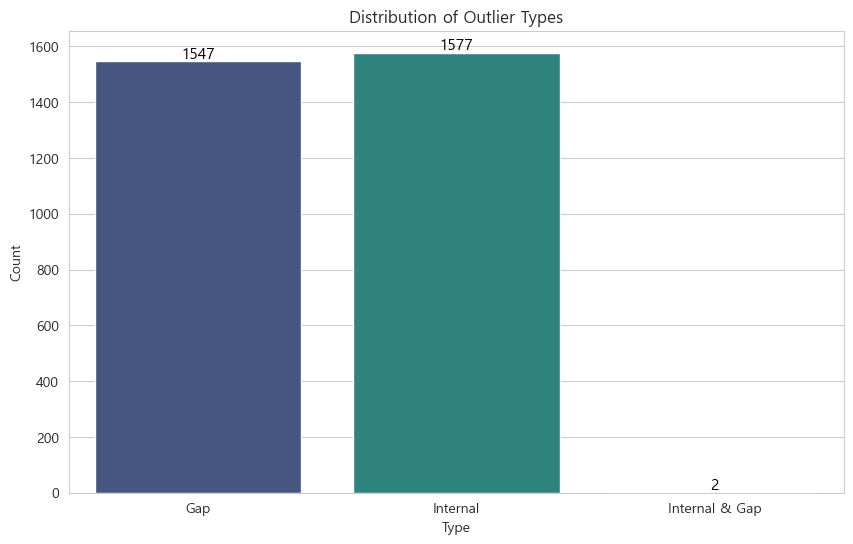

In [20]:
plt.figure(figsize=(10, 6))
sns.countplot(x='outlier_type', data=df, palette='viridis')
plt.title('Distribution of Outlier Types')
plt.xlabel('Type')
plt.ylabel('Count')

# 값 표시
for p in plt.gca().patches:
    plt.gca().annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='center', fontsize=11, color='black', xytext=(0, 5), 
                textcoords='offset points')
plt.show()

## 2. 게임별 이상치 집중도 (Top 20)
특정 게임에서 데이터 품질 문제가 집중적으로 발생하는지 확인합니다.

C:\Users\user\AppData\Local\Temp\ipykernel_8968\920164199.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_games.index.astype(str), y=top_games.values, palette='coolwarm')


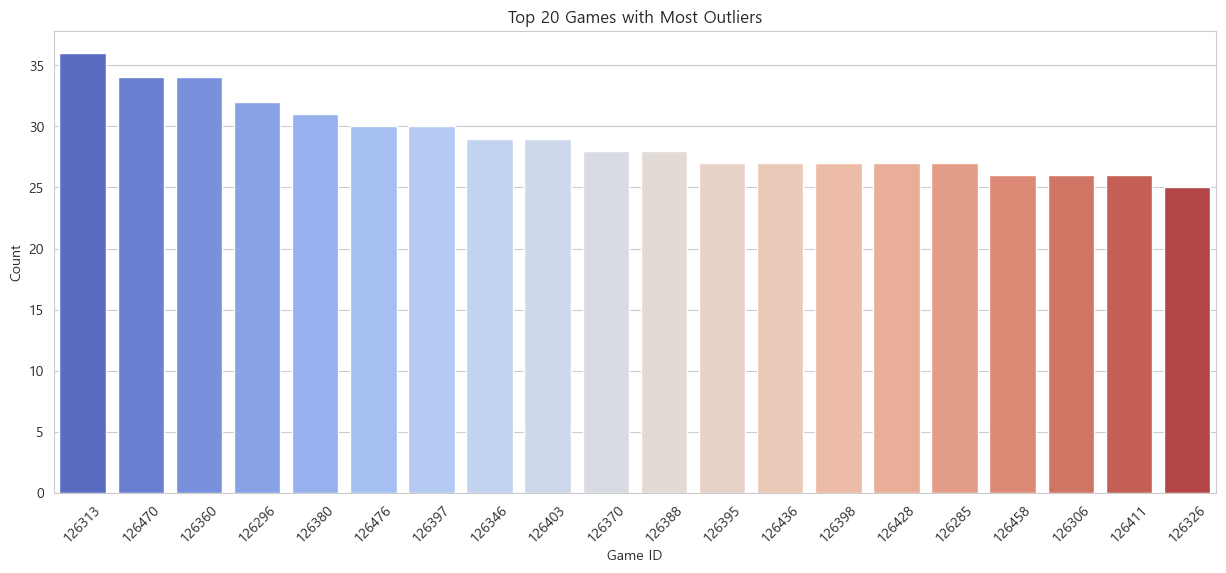

In [21]:
plt.figure(figsize=(15, 6))
top_games = df['game_id'].value_counts().head(20)
sns.barplot(x=top_games.index.astype(str), y=top_games.values, palette='coolwarm')
plt.title('Top 20 Games with Most Outliers')
plt.xlabel('Game ID')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.show()

## 3. 액션 타입별 이상치 분석
어떤 액션 유형에서 주로 이상치가 발생하는지 파악합니다. (예: Carry, Pass Received)

C:\Users\user\AppData\Local\Temp\ipykernel_8968\2683119672.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y=type_counts.index, x=type_counts.values, orient='h', palette='magma')


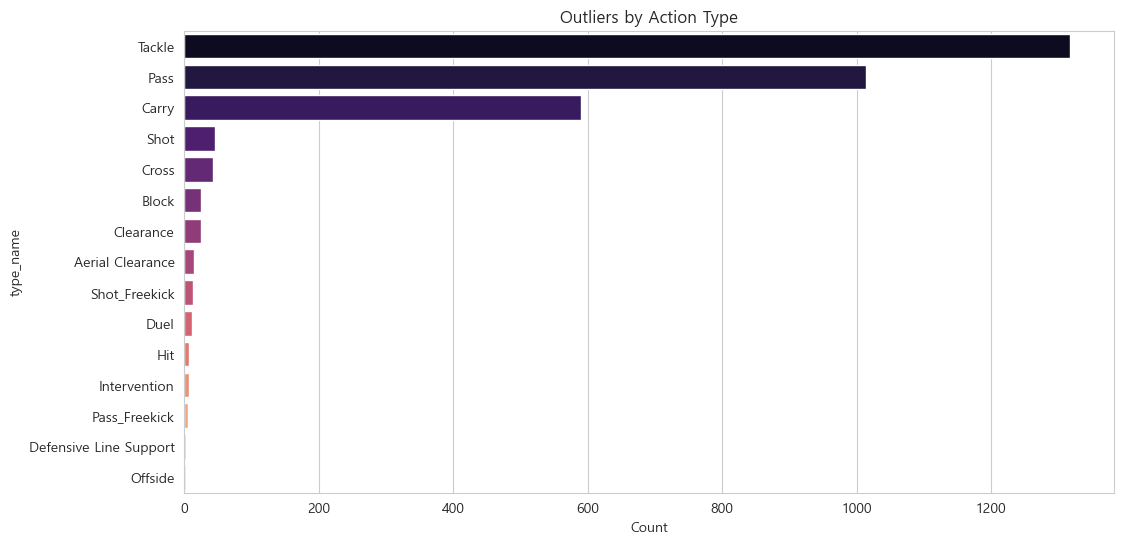

In [22]:
plt.figure(figsize=(12, 6))
type_counts = df['type_name'].value_counts().head(15)
sns.barplot(y=type_counts.index, x=type_counts.values, orient='h', palette='magma')
plt.title('Outliers by Action Type')
plt.xlabel('Count')
plt.show()

## 4. 이상치 발생 위치 시각화 (Spatial Distribution)
데이터 오류가 자주 발생하는 특정 구역이 있는지 확인합니다 (예: 코너 플래그 근처, 센터 서클 등).

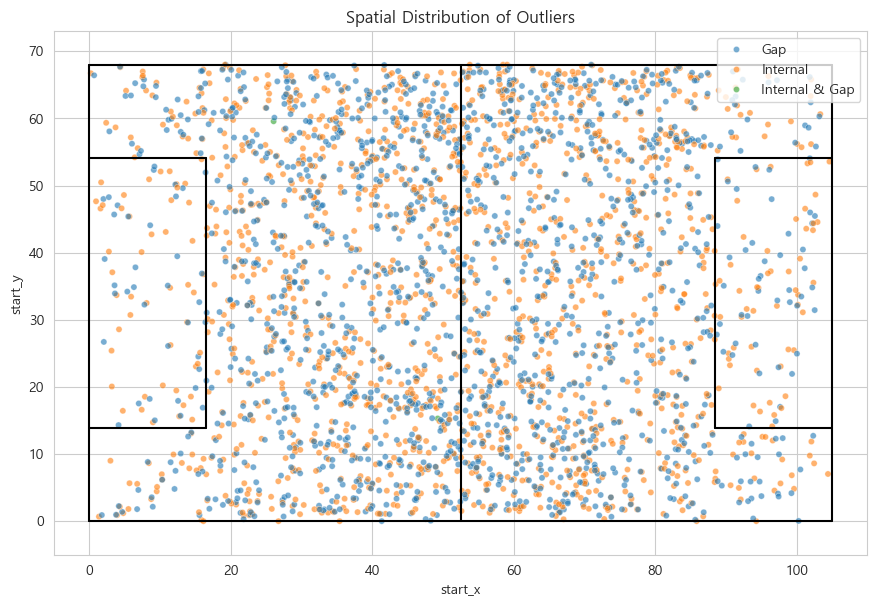

In [23]:
def draw_pitch(ax):
    # Pitch Outline & Centre Line
    ax.plot([0, 0], [0, 68], color="black")
    ax.plot([0, 105], [68, 68], color="black")
    ax.plot([105, 105], [68, 0], color="black")
    ax.plot([105, 0], [0, 0], color="black")
    ax.plot([52.5, 52.5], [0, 68], color="black")

    # Penalty Area
    ax.plot([16.5, 16.5], [13.84, 54.16], color="black")
    ax.plot([0, 16.5], [13.84, 13.84], color="black")
    ax.plot([16.5, 0], [54.16, 54.16], color="black")
    ax.plot([88.5, 88.5], [13.84, 54.16], color="black")
    ax.plot([105, 88.5], [13.84, 13.84], color="black")
    ax.plot([88.5, 105], [54.16, 54.16], color="black")

    # Prepare Scatter Data
    # 정규화된 좌표(0~1)라면 105, 68을 곱해줘야 함.
    # 현재 데이터는 이미 105x68로 환산된 것으로 가정하거나 확인 필요.
    # find_outliers.py 저장 로직상 원본 값(정규화 후 값)을 저장했을 가능성이 큼
    # preprocessed_data는 0~1 정규화가 되어 있음. -> 시각화 시 105/68 곱해주기
    
    return ax

fig, ax = plt.subplots(figsize=(10.5, 6.8))
draw_pitch(ax)

# 좌표 스케일링 (0~1 -> 105x68)
x = df['start_x'] * 105
y = df['start_y'] * 68

sns.scatterplot(x=x, y=y, hue=df['outlier_type'], alpha=0.6, s=20, ax=ax)
plt.title('Spatial Distribution of Outliers')
plt.legend(loc='upper right')
plt.xlim(-5, 110)
plt.ylim(-5, 73)
plt.show()

## 5. 극단값(Extreme Cases) 상세 조회
속도가 가장 높은 상위 10개 케이스를 조회하여 어떤 상황인지 짐작해봅니다.

In [ ]:
cols = ['dt_to_next', 'player_name_ko', 'type_name','internal_speed', 'start_x', 'start_y', 'end_x', 'end_y']
print("Top 10 Extreme Internal Speeds:")
df['start_x'] = df['start_x'] * 105
df['start_y'] = df['start_y'] * 68
df['end_x'] = df['end_x'] * 105
df['end_y'] = df['end_y'] * 68
display(df.sort_values('internal_speed', ascending=False)[cols].head(10))

print("Top 10 Extreme Gap Speeds:")
display(df.sort_values('gap_speed', ascending=False)[cols].head(10))

Top 10 Extreme Internal Speeds:


,dt_to_next,player_name_ko,type_name,internal_speed,start_x,start_y,end_x,end_y
2097,0.001,김강국,Pass_Freekick,33705.920535,25.362960,65.075388,16.024890,32.688824
836,0.006,심상민,Clearance,5271.644814,19.335225,62.863940,50.275890,56.297064
2905,0.001,무고사,Pass,5169.739650,63.350385,24.481972,66.265920,20.212796
1001,0.003,이건희,Pass,4764.097707,78.775620,53.516408,67.487175,44.750528
398,0.007,이호재,Pass,4760.882451,42.527835,8.674216,9.859500,2.085288
1875,0.006,김대원,Pass,3757.305619,29.213835,30.414088,26.996865,52.848648
2550,0.007,안현범,Carry,3394.129647,47.093025,38.162008,33.740700,57.814008
2144,0.001,안데르손,Shot,2712.734954,81.858735,45.850156,83.785170,43.940240
2897,0.003,김준범,Pass,2374.703867,69.908580,2.123300,68.404245,9.086772
838,0.009,켈빈,Pass,2284.264720,75.597900,63.053660,56.920920,54.461948


Top 10 Extreme Gap Speeds:


,dt_to_next,player_name_ko,type_name,internal_speed,start_x,start_y,end_x,end_y
301,0.000,안톤,Duel,NaN,6.557250,37.814188,3.630375,28.700284
2906,1.399,전민광,Tackle,0.000000,63.035490,24.837612,63.035490,24.837612
837,6.025,유리 조나탄,Tackle,0.000000,18.898005,61.027688,18.898005,61.027688
399,4.200,이재원,Tackle,0.000000,42.186060,8.067180,42.186060,8.067180
1002,1.239,김현우,Tackle,0.000000,78.146880,52.626560,78.146880,52.626560
1876,2.156,요니치,Tackle,0.000000,28.875315,30.901240,28.875315,30.901240
1498,1.699,안데르손,Carry,6.793046,69.897870,26.196796,60.829965,33.336592
2551,2.900,제르소,Tackle,0.000000,47.072025,37.923872,47.072025,37.923872
1019,2.304,벨톨라,Tackle,0.000000,33.123510,20.018792,33.123510,20.018792
839,3.250,김태환,Tackle,0.000000,75.896940,62.273312,75.896940,62.273312


: 